> **Versão anterior, fora da entrega atual.** Execute `2.0.1-minerva-modelo-preditivo.ipynb`; este notebook conserva um protocolo anterior e não publica a curva usada atualmente pelo otimizador.

# Modelo preditivo de demanda: Minerva

**Pergunta:** como preço e calendário explicam e permitem prever o volume diário de `Produto_A`, em
quilogramas, num horizonte de duas semanas?

Este notebook reúne, num só lugar, o que antes estava dividido entre o 2.0 e o 2.0.1: retoma
brevemente as hipóteses do EDA, compara os candidatos já definidos com origens semanais, escolhe o
modelo por uma regra declarada **antes** da execução, ajusta o escolhido em todo o desenvolvimento,
interpreta os coeficientes, apresenta a avaliação final de novembro e salva o resultado.

O horizonte de duas semanas pertence à pergunta preditiva do projeto. Ele é definido aqui sem
decidir como será feita a otimização. As saídas são resultados do estudo preditivo; o formato de
consumo na etapa prescritiva será avaliado depois.

| Termo | Dados | Função |
|---|---|---|
| **Desenvolvimento** | 01/08/2025 a 31/10/2025 (76 dias) | Tudo que pode ser usado para ajustar e escolher modelos |
| **Ajuste** | Parte do desenvolvimento anterior a cada origem | Estimar coeficientes e smearing |
| **Validação** | Duas semanas do desenvolvimento depois de cada origem | Medir o erro e escolher o modelo |
| **Teste** | 03/11/2025 a 14/11/2025, fornecido pela Minerva | Avaliação final única do modelo congelado |

## 1. Hipóteses do EDA

As hipóteses abaixo vêm do EDA (`1.0`) e do estudo anterior (`2.0`). Elas definem os candidatos; não
são testadas de novo aqui além da comparação preditiva da seção 4.

| Hipótese | Origem | Representação |
|---|---|---|
| O volume cai com o preço, com elasticidade aproximadamente constante | Enunciado (`A/p^B`) e EDA | Curva de potência: `ln(volume) ~ ln(preço)` |
| O dia da semana desloca o nível de vendas | EDA | Níveis de calendário (`P0` a `P4`) |
| Terça, quarta e quinta não se distinguem; sexta e fim de semana têm nível próprio | EDA e contrastes HC3 do 2.0 | `P3`: segunda–quinta, sexta, fim de semana |
| A segunda-feira pode ter nível próprio | Contrastes HC3 do 2.0 | `P4`: segunda separada |
| Outra forma funcional serviria igualmente | Verificação | Exponencial (`E1`) e linear (`L1`) |
| Há tendência no tempo | EDA | `T1`, tratada só como sensibilidade |

Memória de volume (lag) ficou fora: no 2.0.1 nenhuma variante passou no critério de decisão e ela
tornaria a etapa prescritiva bem mais complexa.

## 2. Regra de decisão, declarada antes de executar

1. **Origens:** cada segunda-feira do desenvolvimento com pelo menos 30 observações de ajuste e as
   duas semanas seguintes completas no desenvolvimento. O modelo aprende só com o passado e prevê os
   14 dias seguintes, sem reajuste intermediário.
2. **Candidatos válidos:** inclinação de preço negativa em todas as origens e previsão positiva em
   todos os dias. `T1` (tendência) entra na tabela como sensibilidade e **não concorre**.
3. **Métrica primária:** WMAPE semanal (erro do volume total de cada semana, a grandeza da meta).
   Secundárias: RMSE, WMAPE diário e viés.
4. **Zona de equivalência:** candidatos válidos com WMAPE semanal até 2 pontos percentuais acima do
   melhor **e** RMSE até 5% acima do menor RMSE (mesma zona do plano de ação).
5. **Desempate na zona:** menos parâmetros; com o mesmo número, a curva de potência (a inclinação é a
   própria elasticidade); persistindo o empate, menor WMAPE semanal.
6. **Teste de novembro:** consultado uma única vez, depois do congelamento. Não altera a escolha.

Com seis origens, diferenças pequenas entre candidatos não são distinguíveis do ruído entre
períodos. A regra existe justamente para que a escolha nesses casos seja pela simplicidade, e não
pelo acaso de uma décima.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

from src.modeling.demand_curve import (
    file_sha256, model_core_sha256, predict_volume_from_artifact, save_artifact,
    validate_artifact,
)

DATA_PATH = ROOT / 'data/processed/minerva_modelagem_treino.csv'
TESTE_PATH = ROOT / 'data/interim/minerva_holdout.csv'
FIGURES_DIR = ROOT / 'reports/figures'
TABLES_DIR = ROOT / 'reports/tables'
MODELO_PATH = ROOT / 'models/preditivo/curva_demanda.json'
for directory in [FIGURES_DIR, TABLES_DIR, MODELO_PATH.parent]:
    directory.mkdir(parents=True, exist_ok=True)

ORDEM_DIAS = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']
DIAS_UTEIS = ORDEM_DIAS[:5]

# Regra de decisão da seção 2
MINIMO_AJUSTE = 30
HORIZONTE_DIAS = 14
ZONA_WMAPE_SEMANAL = 0.02
ZONA_RMSE = 0.05
CONCORRENTES = ['P0', 'P1', 'P2', 'P3', 'P4', 'E1', 'L1']

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 40)

2026-11-04 09:39:39.254 | INFO     | src.config:<module>:11 - PROJ_ROOT path is: /Users/ngodeny/Documents/mestrado/202602-resolucao_problemas


## 3. Desenvolvimento e origens

Apenas a base de desenvolvimento é carregada. O arquivo de teste só é lido na seção 8.

In [2]:
dados = pd.read_csv(DATA_PATH, parse_dates=['data', 'inicio_semana'])
dados = dados.sort_values('data').reset_index(drop=True)
if dados['data'].duplicated().any():
    raise ValueError('Há datas duplicadas no desenvolvimento.')
if (dados[['volume_kg', 'preco_kg']] <= 0).any().any():
    raise ValueError('Volume e preço devem ser positivos.')
dados['ln_volume'] = np.log(dados['volume_kg'])
dados['ln_preco'] = np.log(dados['preco_kg'])

ultima_data = dados['data'].max()
origens = []
for origem in dados.loc[dados['dia_semana'] == 'Segunda', 'data']:
    ajuste = dados.loc[dados['data'] < origem]
    if len(ajuste) >= MINIMO_AJUSTE and origem + pd.Timedelta(days=11) <= ultima_data:
        if set(ajuste['dia_semana']) != set(ORDEM_DIAS):
            raise ValueError(f'Ajuste sem todos os dias da semana na origem {origem.date()}.')
        origens.append(origem)

linhas = []
for numero, origem in enumerate(origens, start=1):
    ajuste = dados.loc[dados['data'] < origem]
    validacao = dados.loc[
        (dados['data'] >= origem) & (dados['data'] < origem + pd.Timedelta(days=HORIZONTE_DIAS))
    ]
    linhas.append({
        'Rodada': numero, 'Origem': origem.date(),
        'Observações de ajuste': len(ajuste),
        'Validação até': validacao['data'].max().date(),
        'Observações de validação': len(validacao),
        'Volume validado (kg)': round(float(validacao['volume_kg'].sum()), 1),
    })
tabela_origens = pd.DataFrame(linhas).set_index('Rodada')
print(
    f"{len(dados)} observações entre {dados['data'].min().date()} e {ultima_data.date()}; "
    f"{int((~dados['dia_semana'].isin(DIAS_UTEIS)).sum())} de fim de semana."
)
display(tabela_origens)

76 observações entre 2025-08-01 e 2025-10-31; 10 de fim de semana.


,Origem,Observações de ajuste,Validação até,Observações de validação,Volume validado (kg)
Rodada,,,,,
1,2025-09-15,34,2025-09-28,12,161.9
2,2025-09-22,39,2025-10-05,13,148.7
3,2025-09-29,46,2025-10-11,12,313.0
4,2025-10-06,52,2025-10-19,13,530.4
5,2025-10-13,58,2025-10-26,13,375.4
6,2025-10-20,65,2025-10-31,11,144.0


**Resultado das origens.** As regras produziram seis origens, de 15/09 a 20/10. O ajuste cresce de 34 para 65 observações e cada validação tem de 11 a 13 dias. O volume validado varia de 144 a 530 kg: as rodadas 3 a 5, com 313 a 530 kg, são as mais pesadas, e já antecipam que algumas rodadas serão bem mais difíceis que outras. Todas as janelas de ajuste continham os sete dias da semana, condição necessária para estimar `P2`.

## 4. Candidatos e comparação nas origens

| Código | Forma | Calendário |
|---|---|---|
| `P0` | potência | nenhum |
| `P1` | potência | dia útil × fim de semana |
| `P2` | potência | sete dias da semana |
| `P3` | potência | segunda–quinta × sexta × fim de semana |
| `P4` | potência | segunda × terça–quinta × sexta × fim de semana |
| `E1` | exponencial | igual a `P3` |
| `L1` | linear | igual a `P3` |
| `T1` | potência | igual a `P3`, com tendência (sensibilidade) |

Na forma de potência, `ln(volume) ~ ln(preço) + calendário`, com retransformação pelo fator de
smearing de Duan. Na exponencial, `ln(volume) ~ preço/100 + calendário`. Na linear,
`volume ~ preço/100 + calendário`.

In [3]:
MAPAS_CONTEXTO = {
    'none': {dia: 'Geral' for dia in ORDEM_DIAS},
    'weekend': {
        dia: ('Fim_de_semana' if dia in ['Sábado', 'Domingo'] else 'Dia_util')
        for dia in ORDEM_DIAS
    },
    'weekday': {dia: dia for dia in ORDEM_DIAS},
    'grouped': {
        dia: (
            'Segunda_a_Quinta' if dia in ORDEM_DIAS[:4]
            else 'Sexta' if dia == 'Sexta'
            else 'Fim_de_semana'
        )
        for dia in ORDEM_DIAS
    },
    'grouped4': {
        dia: (
            'Segunda' if dia == 'Segunda'
            else 'Terca_a_Quinta' if dia in ORDEM_DIAS[1:4]
            else 'Sexta' if dia == 'Sexta'
            else 'Fim_de_semana'
        )
        for dia in ORDEM_DIAS
    },
}
ORDEM_CONTEXTO = {
    'none': ['Geral'],
    'weekend': ['Dia_util', 'Fim_de_semana'],
    'weekday': ORDEM_DIAS,
    'grouped': ['Segunda_a_Quinta', 'Sexta', 'Fim_de_semana'],
    'grouped4': ['Terca_a_Quinta', 'Segunda', 'Sexta', 'Fim_de_semana'],
}
FAMILIAS_LOG = {'power', 'exponential'}


def especificacao(family='power', calendar='grouped', trend=False):
    return {'family': family, 'calendar': calendar, 'trend': trend}


CANDIDATOS = {
    'P0': especificacao(calendar='none'),
    'P1': especificacao(calendar='weekend'),
    'P2': especificacao(calendar='weekday'),
    'P3': especificacao(),
    'P4': especificacao(calendar='grouped4'),
    'E1': especificacao(family='exponential'),
    'L1': especificacao(family='linear'),
    'T1': especificacao(trend=True),
}


def matriz_desenho(base, spec):
    if spec['family'] == 'power':
        preco = base['ln_preco'].astype(float).rename('ln_preco')
    else:
        preco = (base['preco_kg'].astype(float) / 100).rename('preco_100')
    matriz = pd.DataFrame({'const': 1.0, preco.name: preco}, index=base.index)
    contexto = base['dia_semana'].map(MAPAS_CONTEXTO[spec['calendar']])
    for nome in ORDEM_CONTEXTO[spec['calendar']][1:]:
        matriz[f'contexto_{nome}'] = (contexto == nome).astype(float)
    if spec['trend']:
        matriz['indice_tempo_10'] = base['indice_tempo'].astype(float) / 10
    return matriz


def ajustar(ajuste, spec):
    log = spec['family'] in FAMILIAS_LOG
    resposta = ajuste['ln_volume'] if log else ajuste['volume_kg']
    modelo = sm.OLS(resposta, matriz_desenho(ajuste, spec)).fit()
    smearing = float(np.exp(modelo.resid).mean()) if log else 1.0
    return modelo, smearing


def prever(modelo, smearing, base, spec):
    linear = np.asarray(modelo.predict(matriz_desenho(base, spec)), dtype=float)
    return np.exp(linear) * smearing if spec['family'] in FAMILIAS_LOG else linear


def painel_erros(previsoes):
    real = previsoes['volume_real_kg']
    previsto = previsoes['volume_previsto_kg']
    erro = previsto - real
    semanal = previsoes.groupby('inicio_semana')[['volume_real_kg', 'volume_previsto_kg']].sum()
    erro_semanal = semanal['volume_previsto_kg'] - semanal['volume_real_kg']
    return {
        'WMAPE': float(erro.abs().sum() / real.sum()),
        'MAE': float(erro.abs().mean()),
        'RMSE': float(np.sqrt(np.mean(erro**2))),
        'Erro absoluto mediano': float(erro.abs().median()),
        'Viés (%)': float(erro.sum() / real.sum()),
        'WMAPE semanal': float(erro_semanal.abs().sum() / semanal['volume_real_kg'].sum()),
        'Pior erro semanal (%)': float((erro_semanal.abs() / semanal['volume_real_kg']).max()),
        'Previsão mínima': float(previsto.min()),
    }


def validar(code, spec):
    previsoes, coeficientes = [], []
    for numero, origem in enumerate(origens, start=1):
        ajuste = dados.loc[dados['data'] < origem]
        horizonte = dados.loc[
            (dados['data'] >= origem) & (dados['data'] < origem + pd.Timedelta(days=HORIZONTE_DIAS))
        ]
        modelo, smearing = ajustar(ajuste, spec)
        previsoes.append(pd.DataFrame({
            'candidato': code, 'rodada': numero, 'origem': origem,
            'data': horizonte['data'].to_numpy(),
            'inicio_semana': horizonte['inicio_semana'].to_numpy(),
            'dia_semana': horizonte['dia_semana'].to_numpy(),
            'preco_kg': horizonte['preco_kg'].to_numpy(),
            'volume_real_kg': horizonte['volume_kg'].to_numpy(),
            'volume_previsto_kg': prever(modelo, smearing, horizonte, spec),
        }))
        coeficientes.append({
            'candidato': code, 'rodada': numero, 'origem': origem.date(),
            'Inclinação de preço': float(modelo.params.iloc[1]),
        })
    return pd.concat(previsoes, ignore_index=True), pd.DataFrame(coeficientes)


previsoes_validacao, coeficientes_rodada, linhas_metricas = [], [], []
for code, spec in CANDIDATOS.items():
    previsoes, coeficientes = validar(code, spec)
    previsoes_validacao.append(previsoes)
    coeficientes_rodada.append(coeficientes)
    for rodada, recorte in previsoes.groupby('rodada'):
        linhas_metricas.append({
            'Código': code, 'Rodada': rodada, 'Origem': recorte['origem'].iloc[0].date(),
            **painel_erros(recorte),
        })
previsoes_validacao = pd.concat(previsoes_validacao, ignore_index=True)
coeficientes_rodada = pd.concat(coeficientes_rodada, ignore_index=True)
metricas_rodada = pd.DataFrame(linhas_metricas)

parametros = {code: matriz_desenho(dados, spec).shape[1] for code, spec in CANDIDATOS.items()}
wmape_semanal_rodada = 100 * metricas_rodada.pivot(
    index='Origem', columns='Código', values='WMAPE semanal'
)[list(CANDIDATOS)]
print('WMAPE semanal (%) por origem')
display(wmape_semanal_rodada.round(1))

WMAPE semanal (%) por origem


Código,P0,P1,P2,P3,P4,E1,L1,T1
Origem,,,,,,,,
2025-09-15,34.7,29.0,29.1,25.6,26.1,25.6,27.9,56.2
2025-09-22,72.6,46.7,44.9,46.9,46.4,46.9,49.8,94.7
2025-09-29,36.6,41.5,35.8,35.9,35.8,36.3,39.6,33.0
2025-10-06,49.4,54.2,40.0,41.9,40.4,42.3,46.4,53.3
2025-10-13,46.8,44.8,38.3,37.5,37.4,37.5,35.2,37.6
2025-10-20,25.9,18.3,21.6,20.2,22.7,19.0,57.5,28.7


**Resultado da execução.** O WMAPE semanal de `P3` vai de 20,2% (origem 20/10) a 46,9% (22/09). Os candidatos com calendário detalhado (`P2`, `P3`, `P4` e `E1`) sobem e descem juntos e ficam a menos de 4 pontos entre si em qualquer origem: a dificuldade é do período, não do modelo. Já `P0`, `L1` e `T1` têm rodadas isoladas muito piores, como 72,6% para `P0` e 94,7% para `T1` em 22/09, e 57,5% para `L1` em 20/10.

## 5. Painel comparativo e aplicação da regra

O painel resume cada candidato nas seis origens: média e desvio-padrão (DP) do erro entre origens.
Quando a diferença entre dois candidatos é menor que o DP, a média sozinha não permite afirmar qual
é melhor.

,Parâmetros,WMAPE semanal (%),DP semanal (p.p.),WMAPE diário (%),RMSE (kg),Viés (%),Pior erro semanal (%),Previsão mínima (kg),Válido,Concorre,Na zona de equivalência
Código,,,,,,,,,,,
E1,4,34.60,10.45,37.81,12.66,1.77,43.34,0.71,True,True,True
P3,4,34.69,10.03,37.83,12.61,2.16,43.36,0.73,True,True,True
P4,5,34.79,8.91,39.69,13.10,3.12,43.44,0.70,True,True,True
P2,8,34.94,8.35,42.15,13.47,2.75,43.06,0.50,True,True,False
P1,3,39.09,13.12,50.96,16.78,-2.42,45.62,0.89,True,True,False
L1,4,42.73,10.65,52.32,15.62,-12.44,51.76,-27.67,False,True,False
P0,2,44.35,16.30,70.82,20.00,6.39,56.48,13.53,True,True,False
T1,5,50.60,24.25,52.62,15.20,15.79,66.39,0.78,True,False,False


Candidatos na zona de equivalência: ['P3', 'E1', 'P4']
Escolhido pela regra: P3 (4 parâmetros)


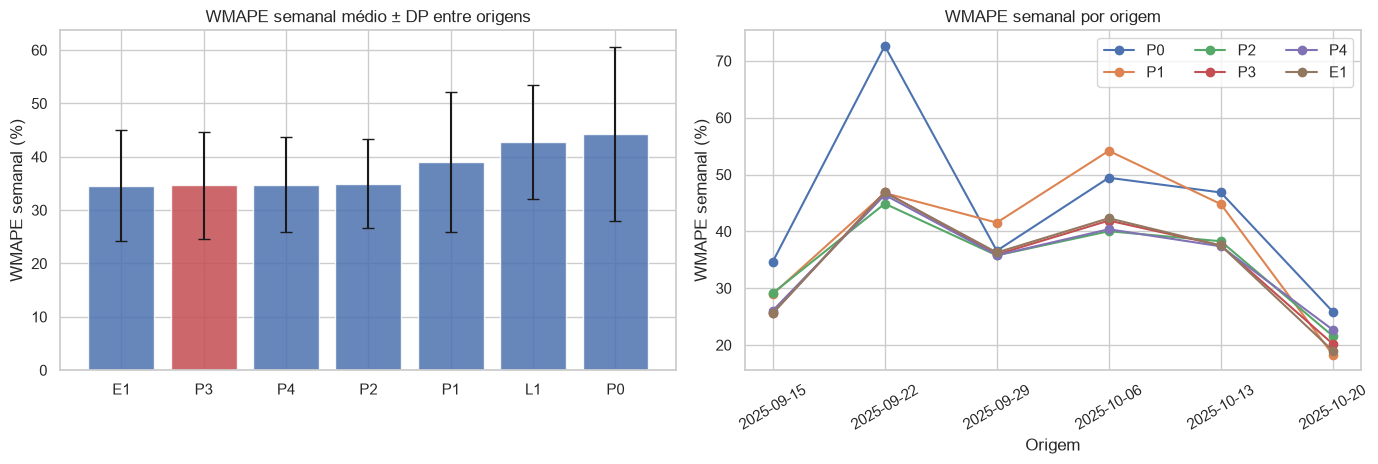

In [4]:
media = metricas_rodada.groupby('Código').mean(numeric_only=True)
desvio = metricas_rodada.groupby('Código').std(numeric_only=True)
inclinacoes = coeficientes_rodada.groupby('candidato')['Inclinação de preço']

painel = pd.DataFrame(index=list(CANDIDATOS))
painel['Parâmetros'] = pd.Series(parametros)
painel['WMAPE semanal (%)'] = 100 * media['WMAPE semanal']
painel['DP semanal (p.p.)'] = 100 * desvio['WMAPE semanal']
painel['WMAPE diário (%)'] = 100 * media['WMAPE']
painel['RMSE (kg)'] = media['RMSE']
painel['Viés (%)'] = 100 * media['Viés (%)']
painel['Pior erro semanal (%)'] = 100 * media['Pior erro semanal (%)']
painel['Previsão mínima (kg)'] = metricas_rodada.groupby('Código')['Previsão mínima'].min()
painel['Válido'] = (inclinacoes.max() < 0) & (painel['Previsão mínima (kg)'] > 0)
painel['Concorre'] = painel.index.isin(CONCORRENTES)
painel.index.name = 'Código'


def aplicar_regra(painel):
    elegiveis = painel.loc[painel['Válido'] & painel['Concorre']]
    melhor_wmape = elegiveis['WMAPE semanal (%)'].min()
    melhor_rmse = elegiveis['RMSE (kg)'].min()
    painel = painel.copy()
    painel['Na zona de equivalência'] = (
        painel['Válido'] & painel['Concorre']
        & (painel['WMAPE semanal (%)'] <= melhor_wmape + 100 * ZONA_WMAPE_SEMANAL)
        & (painel['RMSE (kg)'] <= melhor_rmse * (1 + ZONA_RMSE))
    )
    zona = painel.loc[painel['Na zona de equivalência']].copy()
    zona['potencia_primeiro'] = (~zona.index.isin(
        [c for c, s in CANDIDATOS.items() if s['family'] == 'power']
    )).astype(int)
    zona = zona.sort_values(['Parâmetros', 'potencia_primeiro', 'WMAPE semanal (%)'])
    return painel.sort_values('WMAPE semanal (%)'), zona.index[0], zona


painel, ESCOLHIDO, zona = aplicar_regra(painel)
painel.to_csv(TABLES_DIR / '022_comparacao_candidatos.csv')
metricas_rodada.to_csv(TABLES_DIR / '022_metricas_por_rodada.csv', index=False)
previsoes_validacao.to_csv(TABLES_DIR / '022_previsoes_validacao.csv', index=False)
display(painel.round(2))
print(f"Candidatos na zona de equivalência: {list(zona.index)}")
print(f'Escolhido pela regra: {ESCOLHIDO} ({parametros[ESCOLHIDO]} parâmetros)')
assert not CANDIDATOS[ESCOLHIDO]['trend'] and CANDIDATOS[ESCOLHIDO]['family'] != 'linear'
ESPECIFICACAO = CANDIDATOS[ESCOLHIDO]

fig, eixos = plt.subplots(1, 2, figsize=(14, 4.8))
ordem = [c for c in painel.index if painel.loc[c, 'Concorre']]
eixos[0].bar(
    ordem, painel.loc[ordem, 'WMAPE semanal (%)'],
    yerr=painel.loc[ordem, 'DP semanal (p.p.)'], capsize=4,
    color=['#c44e52' if c == ESCOLHIDO else '#4c72b0' for c in ordem], alpha=0.85,
)
eixos[0].set(title='WMAPE semanal médio ± DP entre origens', ylabel='WMAPE semanal (%)')
for code in ['P0', 'P1', 'P2', 'P3', 'P4', 'E1']:
    eixos[1].plot(
        wmape_semanal_rodada.index.astype(str), wmape_semanal_rodada[code], marker='o', label=code
    )
eixos[1].set(title='WMAPE semanal por origem', xlabel='Origem', ylabel='WMAPE semanal (%)')
eixos[1].tick_params(axis='x', rotation=30)
eixos[1].legend(ncol=3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / '022_comparacao_candidatos.png', dpi=160, bbox_inches='tight')
plt.show()

**Resultado do painel.**

- **Calendário é indispensável.** Sem ele, `P0` tem WMAPE semanal de 44,35% e diário de 70,82%. `P1`, que separa só o fim de semana, tem 39,09% e 50,96%, e fica 4,5 p.p. acima do melhor.
- **`P3`, `E1`, `P4` e `P2` empatam no semanal**, entre 34,60% e 34,94%. A diferença entre eles (0,35 p.p.) é muito menor que o DP entre origens (8 a 10 p.p.). O erro diário os separa um pouco: `P3` e `E1` têm 37,8%, `P4` 39,7% e `P2` 42,2%.
- **`L1` é inválida:** prevê volume de até −27,67 kg e tem viés de −12,4%.
- **`T1` (sensibilidade, não concorre):** a tendência extrapolada por duas semanas dispara o erro, com WMAPE semanal de 50,60%, DP de 24,25 p.p. e viés de +15,8%.
- **Zona de equivalência:** o melhor WMAPE semanal é 34,60% (`E1`), então o limite é 36,60%; o menor RMSE é 12,61 kg (`P3`), então o limite é 13,24 kg. Ficam na zona `P3`, `E1` e `P4`. `P2` sai pelo RMSE (13,47 kg), e `P1` e `P0` saem pelo WMAPE.

**Escolha.** Aplicada a regra declarada na seção 2, o modelo escolhido é **`P3`**: curva de potência com preço e três níveis de calendário (segunda a quinta, sexta, fim de semana), quatro parâmetros.

Dentro da zona de equivalência, `P4` tem 5 parâmetros, e `E1` tem os mesmos 4 de `P3`, mas na forma exponencial; o desempate pela forma de potência vale porque a inclinação de `ln(preço)` é a própria elasticidade. **O erro não separa `P3`, `E1` e `P4`.** A escolha é por simplicidade e interpretação, não por superioridade medida. O que `P4` acrescentaria é um nível próprio para a segunda-feira; no 2.0, isso corrigia o viés das segundas (de −21,5% para +4,1%) ao custo de piorar terça a quinta, e aqui piora o WMAPE diário em 1,9 ponto sem ganho semanal.

## 6. Ajuste final no desenvolvimento

O modelo escolhido é ajustado com as 76 observações do desenvolvimento. Os erros-padrão são HC3,
porque os resíduos têm variância não constante.

In [5]:
modelo_final, smearing_final = ajustar(dados, ESPECIFICACAO)
modelo_hc3 = modelo_final.get_robustcov_results(cov_type='HC3')
tabela_coeficientes = pd.DataFrame({
    'coeficiente': modelo_final.params.to_numpy(),
    'erro_padrao_HC3': modelo_hc3.bse,
    'p_valor_HC3': modelo_hc3.pvalues,
    'IC95_inferior': modelo_hc3.conf_int()[:, 0],
    'IC95_superior': modelo_hc3.conf_int()[:, 1],
}, index=modelo_final.model.exog_names)
tabela_coeficientes.index.name = 'variavel'
tabela_coeficientes.to_csv(TABLES_DIR / '022_coeficientes.csv')
display(tabela_coeficientes.round(4))
print(f'Smearing de Duan: {smearing_final:.4f} | observações: {int(modelo_final.nobs)}')
print(f'R² (escala log): {modelo_final.rsquared:.3f} | BIC: {modelo_final.bic:.1f}')

,coeficiente,erro_padrao_HC3,p_valor_HC3,IC95_inferior,IC95_superior
variavel,,,,,
const,91.5915,19.0853,0.0,53.5456,129.6373
ln_preco,-12.3647,2.6696,0.0,-17.6864,-7.0430
contexto_Sexta,-1.3394,0.1508,0.0,-1.6401,-1.0388
contexto_Fim_de_semana,-2.9670,0.2982,0.0,-3.5615,-2.3725


Smearing de Duan: 1.1226 | observações: 76
R² (escala log): 0.818 | BIC: 130.8


**Resultado do ajuste.** A equação estimada é:

`ln(volume) = 91,5915 − 12,3647 × ln(preço) − 1,3394 × I(sexta) − 2,9670 × I(fim de semana)`.

- **Elasticidade:** o coeficiente de `ln(preço)` é −12,36, com intervalo HC3 de 95% de −17,69 a −7,04. Dentro da faixa observada, 1% a mais no preço está associado a uma queda média de cerca de 12,4% no volume, no mesmo contexto. O sinal negativo é robusto; a magnitude é alta e incerta.
- **Calendário:** sexta vende cerca de 74% menos que segunda a quinta (`e^−1,34 ≈ 0,26`), e o fim de semana cerca de 95% menos (`e^−2,97 ≈ 0,05`), tudo mais constante. O fim de semana tem só 10 observações.
- **Smearing de Duan:** 1,1226. O R² na escala logarítmica é 0,82.

A leitura é de resposta preditiva observacional, e não de efeito causal: o preço pode ter sido definido em reação à demanda esperada.

## 7. Diagnósticos essenciais

Resíduos, dependência temporal, influência de observações isoladas e suporte de preço dos dados.

,Diagnóstico,Resultado
0,Breusch-Pagan p-valor,0.0175
1,Durbin-Watson,1.8282
2,Ljung-Box p-valor lag 1,0.5139
3,Ljung-Box p-valor lag 5,0.9428


Cook > 4/n: 5 observações | alavancagem > 2p/n: 7 observações
Coeficiente de preço: completo -12.36; sem uma observação, de -14.10 a -11.20


,data,dia_semana,volume_kg,preco_kg,cook,alavancagem,coef_preco_sem_observacao
57,2025-10-11,Sábado,0.588,1188.86,0.523,0.159,-14.099
22,2025-08-30,Sábado,3.684,1294.79,0.200,0.106,-12.793
64,2025-10-19,Domingo,0.588,1233.57,0.167,0.111,-12.865
68,2025-10-23,Quinta,2.824,1344.63,0.130,0.058,-11.199
11,2025-08-15,Sexta,3.790,1243.81,0.056,0.079,-12.660


,n,min,max
contexto,,,
Segunda_a_Quinta,52,1201.63,1352.42
Sexta,14,1208.37,1365.49
Fim_de_semana,10,1188.86,1354.19


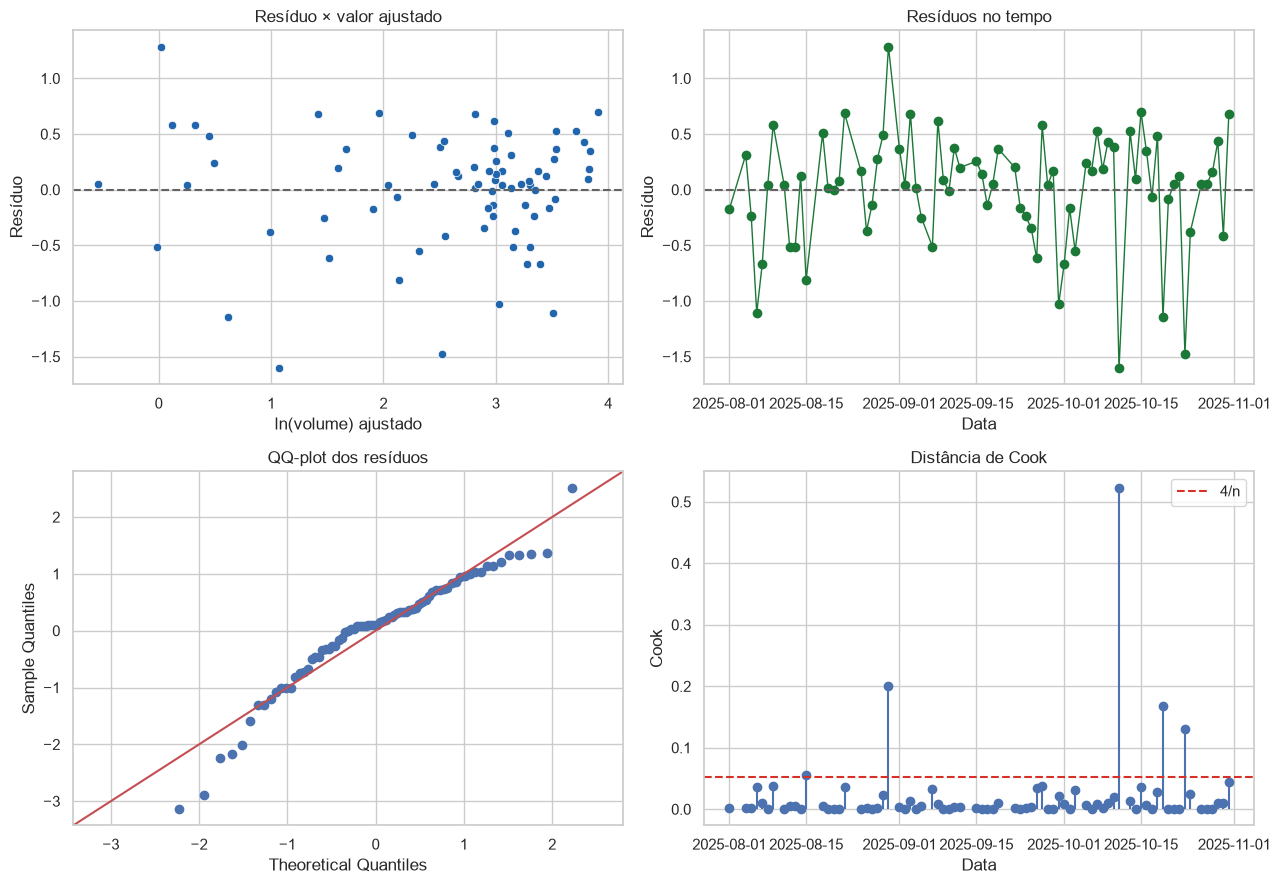

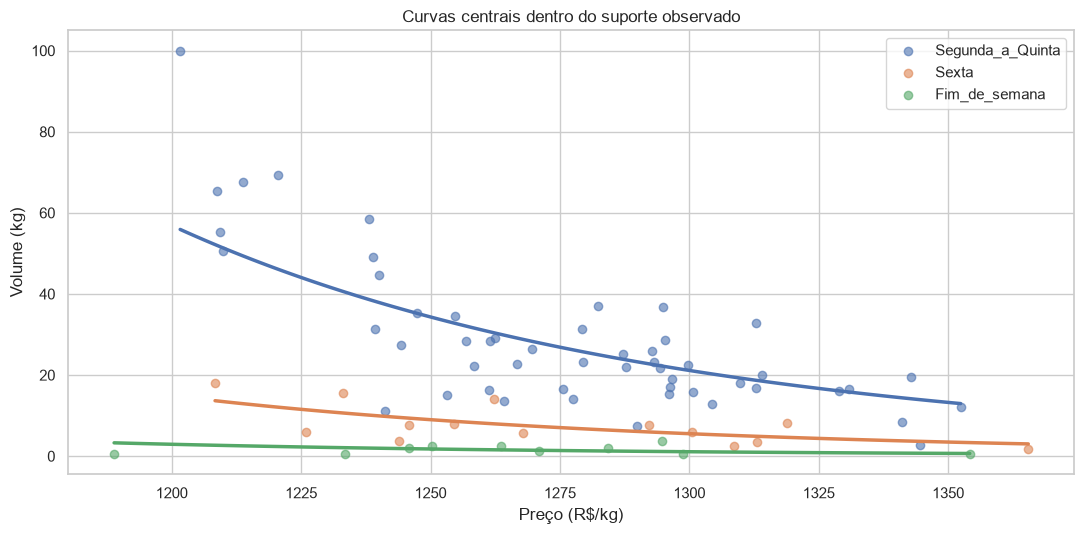

In [6]:
matriz_final = matriz_desenho(dados, ESPECIFICACAO)
residuos = modelo_final.resid
bp_lm, bp_p, _, _ = het_breuschpagan(residuos, matriz_final)
ljung_box = acorr_ljungbox(residuos, lags=[1, 5], return_df=True)
diagnosticos = pd.DataFrame({
    'Diagnóstico': [
        'Breusch-Pagan p-valor', 'Durbin-Watson',
        'Ljung-Box p-valor lag 1', 'Ljung-Box p-valor lag 5',
    ],
    'Resultado': [
        bp_p, float(durbin_watson(residuos)),
        ljung_box.loc[1, 'lb_pvalue'], ljung_box.loc[5, 'lb_pvalue'],
    ],
})
diagnosticos.to_csv(TABLES_DIR / '022_diagnosticos_residuos.csv', index=False)
display(diagnosticos.round(4))

influencia = modelo_final.get_influence()
cook = influencia.cooks_distance[0]
alavancagem = influencia.hat_matrix_diag
nome_preco = modelo_final.model.exog_names[1]
elasticidade_loo = [
    float(ajustar(dados.drop(index=i), ESPECIFICACAO)[0].params[nome_preco]) for i in dados.index
]
coef_preco = float(modelo_final.params[nome_preco])
tabela_influencia = pd.DataFrame({
    'data': dados['data'], 'dia_semana': dados['dia_semana'],
    'volume_kg': dados['volume_kg'], 'preco_kg': dados['preco_kg'],
    'cook': cook, 'alavancagem': alavancagem, 'coef_preco_sem_observacao': elasticidade_loo,
})
tabela_influencia.to_csv(TABLES_DIR / '022_influencia.csv', index=False)
limite_cook = 4 / len(dados)
limite_alavancagem = 2 * matriz_final.shape[1] / len(dados)
print(
    f'Cook > 4/n: {int((cook > limite_cook).sum())} observações | '
    f'alavancagem > 2p/n: {int((alavancagem > limite_alavancagem).sum())} observações'
)
print(
    f'Coeficiente de preço: completo {coef_preco:.2f}; sem uma observação, '
    f'de {min(elasticidade_loo):.2f} a {max(elasticidade_loo):.2f}'
)
display(tabela_influencia.nlargest(5, 'cook').round({'volume_kg': 3, 'preco_kg': 2, 'cook': 3, 'alavancagem': 3, 'coef_preco_sem_observacao': 3}))

contexto_dev = dados['dia_semana'].map(MAPAS_CONTEXTO[ESPECIFICACAO['calendar']])
suporte_preco = (
    dados.assign(contexto=contexto_dev).groupby('contexto')
    .agg(n=('preco_kg', 'size'), min=('preco_kg', 'min'), max=('preco_kg', 'max'))
    .reindex(ORDEM_CONTEXTO[ESPECIFICACAO['calendar']])
)
suporte_preco.to_csv(TABLES_DIR / '022_suporte_preco.csv')
display(suporte_preco.round(2))

fig, eixos = plt.subplots(2, 2, figsize=(13, 9))
sns.scatterplot(x=modelo_final.fittedvalues, y=residuos, ax=eixos[0, 0], color='#2166ac')
eixos[0, 0].axhline(0, color='#636363', linestyle='--')
eixos[0, 0].set(title='Resíduo × valor ajustado', xlabel='ln(volume) ajustado', ylabel='Resíduo')
eixos[0, 1].plot(dados['data'], residuos, marker='o', linewidth=1, color='#1b7837')
eixos[0, 1].axhline(0, color='#636363', linestyle='--')
eixos[0, 1].set(title='Resíduos no tempo', xlabel='Data', ylabel='Resíduo')
sm.qqplot(residuos, line='45', fit=True, ax=eixos[1, 0])
eixos[1, 0].set_title('QQ-plot dos resíduos')
eixos[1, 1].stem(dados['data'], cook, basefmt=' ')
eixos[1, 1].axhline(limite_cook, color='#d73027', linestyle='--', label='4/n')
eixos[1, 1].set(title='Distância de Cook', xlabel='Data', ylabel='Cook')
eixos[1, 1].legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / '022_diagnosticos.png', dpi=160, bbox_inches='tight')
plt.show()

if ESPECIFICACAO['calendar'] == 'grouped':
    dia_representativo = {'Segunda_a_Quinta': 'Segunda', 'Sexta': 'Sexta', 'Fim_de_semana': 'Sábado'}
else:
    dia_representativo = {
        contexto: next(d for d, c in MAPAS_CONTEXTO[ESPECIFICACAO['calendar']].items() if c == contexto)
        for contexto in suporte_preco.index
    }
fig, ax = plt.subplots(figsize=(11, 5.5))
paleta = sns.color_palette('deep', len(suporte_preco))
for cor, (contexto, linha) in zip(paleta, suporte_preco.iterrows()):
    pontos = dados.loc[contexto_dev == contexto]
    ax.scatter(pontos['preco_kg'], pontos['volume_kg'], alpha=0.6, color=cor, label=contexto)
    grade = np.linspace(linha['min'], linha['max'], 100)
    base_curva = pd.DataFrame({
        'preco_kg': grade, 'ln_preco': np.log(grade),
        'dia_semana': dia_representativo[contexto], 'indice_tempo': 0,
    })
    ax.plot(grade, prever(modelo_final, smearing_final, base_curva, ESPECIFICACAO), color=cor, linewidth=2.5)
ax.set(title='Curvas centrais dentro do suporte observado', xlabel='Preço (R$/kg)', ylabel='Volume (kg)')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / '022_curvas_suporte.png', dpi=160, bbox_inches='tight')
plt.show()

**Resultado dos diagnósticos.**

- **Variância:** Breusch–Pagan com p = 0,0175 indica variância não constante dos resíduos, o que justifica os erros-padrão HC3.
- **Dependência temporal:** Durbin–Watson de 1,83 e Ljung–Box com p = 0,51 (lag 1) e 0,94 (lag 5). Não há evidência de autocorrelação residual curta.
- **Caudas:** o QQ-plot mostra cauda inferior mais pesada, com alguns resíduos muito negativos em dias de volume baixo. Intervalos que dependam de normalidade seriam otimistas.
- **Influência:** cinco observações superam 4/n em Cook e sete superam 2p/n em alavancagem. A mais influente é o sábado 11/10, com 0,59 kg ao menor preço do suporte (Cook de 0,52). Mesmo assim, o coeficiente de preço, retirando uma observação por vez, vai de −14,10 a −11,20 e preserva o sinal.
- **Suporte de preço:** segunda a quinta tem 52 observações, entre R$ 1.201,63 e R$ 1.352,42; sexta tem 14, entre R$ 1.208,37 e R$ 1.365,49; fim de semana tem 10, entre R$ 1.188,86 e R$ 1.354,19. As curvas só devem ser usadas dentro dessas faixas.

## 8. Congelamento e avaliação final em novembro

O modelo é gravado **antes** de o arquivo de teste ser lido, com o hash do núcleo preditivo. Depois
da avaliação, o hash é conferido: ele não pode ter mudado. A escolha do modelo não é revista.

In [7]:
spec = ESPECIFICACAO
nomes = list(modelo_final.model.exog_names)
contextos = ORDEM_CONTEXTO[spec['calendar']]
artefato = {
    'artifact_version': 2,
    'model_id': f'{ESCOLHIDO}-{spec["family"]}-{spec["calendar"]}-preditivo',
    'family': spec['family'],
    'calendar': {
        'baseline': contextos[0], 'contexts': contextos,
        'mapping': MAPAS_CONTEXTO[spec['calendar']], 'source_variable': 'dia_semana',
    },
    'feature_order': nomes,
    'coefficients': {nome: float(modelo_final.params[nome]) for nome in nomes},
    'smearing_factor': smearing_final,
    'price_support': {
        contexto: {'min': float(l['min']), 'max': float(l['max']), 'n': int(l['n'])}
        for contexto, l in suporte_preco.iterrows()
    },
    'formula': 'ln(volume_kg) ~ ln(preco_kg) + calendário' if spec['family'] == 'power'
    else 'ln(volume_kg) ~ preco_kg/100 + calendário',
    'training': {
        'data_file': 'data/processed/minerva_modelagem_treino.csv',
        'data_sha256': file_sha256(DATA_PATH), 'rows': int(len(dados)),
        'start': str(dados['data'].min().date()), 'end': str(dados['data'].max().date()),
    },
    'selection': {
        'protocol': 'weekly_origins_two_week_horizon_fixed_model',
        'origins': [str(o.date()) for o in origens],
        'candidates_compared': CONCORRENTES, 'chosen': ESCOLHIDO,
        'wmape_weekly_mean': float(painel.loc[ESCOLHIDO, 'WMAPE semanal (%)'] / 100),
    },
    'diagnostics': {
        'breusch_pagan_p_value': float(bp_p), 'durbin_watson': float(durbin_watson(residuos)),
        'ljung_box_p_value_lag_5': float(ljung_box.loc[5, 'lb_pvalue']),
    },
    'observational_warning': (
        'Curva preditiva observacional; preço pode refletir demanda antecipada e variáveis '
        'omitidas. Não interpretar como efeito causal identificado.'
    ),
}
artefato['model_core_sha256'] = model_core_sha256(artefato)
validate_artifact(artefato)
save_artifact(artefato, MODELO_PATH)
hash_congelado = artefato['model_core_sha256']
print(f'Modelo congelado em {MODELO_PATH.relative_to(ROOT)}')
print(f'Hash do núcleo: {hash_congelado}')

Modelo congelado em models/preditivo/curva_demanda.json
Hash do núcleo: 59884fba38c28618142678475c8093ea9b65f9511c75e7161665dc1278f84964


,WMAPE (%),MAE (kg),RMSE (kg),Viés (%),WMAPE semanal (%)
0,36.28,6.66,8.53,-16.21,16.77


,volume_real_kg,volume_previsto_kg,erro_kg,erro_%
inicio_semana,,,,
2025-11-03,74.24,74.76,0.52,0.70
2025-11-10,109.39,79.11,-30.28,-27.68


Preços fora do suporte: nenhum
Fim de semana no teste: False
Diferença máxima entre notebook e módulo de inferência: 1.42e-13 kg
Hash inalterado após o teste: True


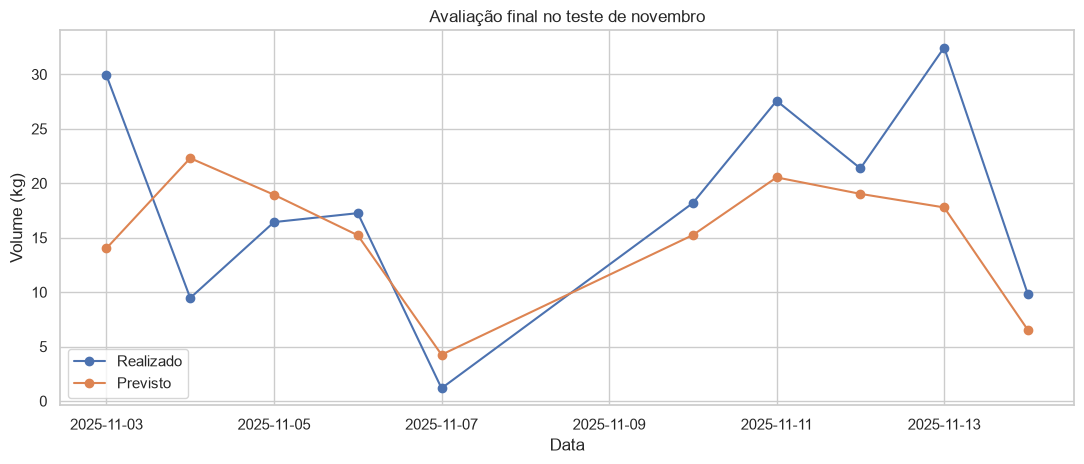

In [8]:
teste_raw = pd.read_csv(TESTE_PATH, parse_dates=['Data']).sort_values('Data')
teste = pd.DataFrame({
    'data': teste_raw['Data'],
    'volume_real_kg': teste_raw['Volume Realizado (kg)'].astype(float),
    'preco_kg': teste_raw['Receita Realizada (R$)'] / teste_raw['Volume Realizado (kg)'],
}).reset_index(drop=True)
teste['numero_dia_semana'] = teste['data'].dt.dayofweek
teste['dia_semana'] = teste['numero_dia_semana'].map(dict(enumerate(ORDEM_DIAS)))
teste['inicio_semana'] = teste['data'] - pd.to_timedelta(teste['numero_dia_semana'], unit='D')
teste['contexto'] = teste['dia_semana'].map(MAPAS_CONTEXTO[spec['calendar']])
teste['ln_preco'] = np.log(teste['preco_kg'])
teste['volume_previsto_kg'] = prever(modelo_final, smearing_final, teste, spec)
teste['erro_kg'] = teste['volume_previsto_kg'] - teste['volume_real_kg']

fora_do_suporte = [
    (str(l.data.date()), round(l.preco_kg, 2)) for l in teste.itertuples()
    if not suporte_preco.loc[l.contexto, 'min'] <= l.preco_kg <= suporte_preco.loc[l.contexto, 'max']
]
metricas_teste = painel_erros(teste)
semanal_teste = teste.groupby('inicio_semana')[['volume_real_kg', 'volume_previsto_kg']].sum()
semanal_teste['erro_kg'] = semanal_teste['volume_previsto_kg'] - semanal_teste['volume_real_kg']
semanal_teste['erro_%'] = 100 * semanal_teste['erro_kg'] / semanal_teste['volume_real_kg']

# O módulo de inferência do projeto deve reproduzir as previsões do notebook.
via_modulo = np.array([
    predict_volume_from_artifact(MODELO_PATH, p, d, allow_extrapolation=True)
    for p, d in zip(teste['preco_kg'], teste['dia_semana'])
])
diferenca_modulo = float(np.max(np.abs(via_modulo - teste['volume_previsto_kg'])))
hash_depois = model_core_sha256(json.loads(MODELO_PATH.read_text(encoding='utf-8')))

teste.to_csv(TABLES_DIR / '022_previsoes_teste.csv', index=False)
resumo_teste = pd.DataFrame([{
    'WMAPE (%)': 100 * metricas_teste['WMAPE'], 'MAE (kg)': metricas_teste['MAE'],
    'RMSE (kg)': metricas_teste['RMSE'], 'Viés (%)': 100 * metricas_teste['Viés (%)'],
    'WMAPE semanal (%)': 100 * metricas_teste['WMAPE semanal'],
}])
resumo_teste.to_csv(TABLES_DIR / '022_metricas_teste.csv', index=False)
display(resumo_teste.round(2))
display(semanal_teste.round(2))
print(f'Preços fora do suporte: {fora_do_suporte or "nenhum"}')
print(f'Fim de semana no teste: {bool((~teste["dia_semana"].isin(DIAS_UTEIS)).any())}')
print(f'Diferença máxima entre notebook e módulo de inferência: {diferenca_modulo:.2e} kg')
print(f'Hash inalterado após o teste: {hash_depois == hash_congelado}')

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(teste['data'], teste['volume_real_kg'], marker='o', label='Realizado')
ax.plot(teste['data'], teste['volume_previsto_kg'], marker='o', label='Previsto')
ax.set(title='Avaliação final no teste de novembro', xlabel='Data', ylabel='Volume (kg)')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / '022_teste.png', dpi=160, bbox_inches='tight')
plt.show()

## 9. Resultado do teste e conclusões

**Resultado do teste.** O modelo congelado tem WMAPE diário de 36,28%, MAE de 6,66 kg, RMSE de 8,53 kg, viés de −16,21% e WMAPE semanal de 16,77%. Os dez preços estão dentro do suporte de seus contextos, e o hash do núcleo não mudou. O módulo de inferência do projeto reproduz as previsões do notebook com diferença máxima de 1,4 × 10⁻¹³ kg.

- **Semana de 03/11:** previsto 74,76 kg contra 74,24 kg realizados (+0,7%).
- **Semana de 10/11:** previsto 79,11 kg contra 109,39 kg realizados (−27,7%). O viés de subestimação vem dessa semana.
- **Comparação com a validação:** o WMAPE diário é parecido (36,28% contra 37,83% de `P3` na validação). O semanal é menor, mas são só duas semanas, com erros de sinais opostos; esse número não deve ser lido como melhora real.
- **Limite do teste:** ele contém apenas dias úteis e não avalia o comportamento de fim de semana.

### Conclusões

1. **O calendário é necessário:** sem ele, o WMAPE semanal sobe de 34,69% para 44,35% e o diário de 37,83% para 70,82%.
2. **`P3`, `E1`, `P4` e `P2` não se distinguem no erro semanal.** A regra declarada escolheu `P3` por ter menos parâmetros e forma de potência, não por ter vencido.
3. **A forma linear é inválida e a tendência piora a previsão** quando precisa ser extrapolada por duas semanas.
4. **A elasticidade estimada é −12,36** (HC3 de −17,69 a −7,04), estável em sinal quando se retira uma observação por vez, mas alta e de magnitude incerta.
5. **No teste de novembro**, o WMAPE diário foi de 36,28% e o semanal de 16,77%, com subestimação de 16,2% concentrada na segunda semana.
6. **O modelo está congelado** em `models/preditivo/curva_demanda.json`, com suporte de preço e hash, pronto para ser consumido depois.

### Limitações

São seis origens de duas semanas e 76 observações, só 10 de fim de semana; diferenças de décimos entre candidatos não são distinguíveis do ruído entre períodos. As hipóteses de calendário vieram do EDA sobre a amostra inteira, de modo que a validação mede o ajuste dado esse calendário, e o teste de novembro, com dez dias úteis, é a única checagem que não passou pela seleção. O erro semanal continua alto (pior semana média de 43%): a curva captura o comportamento médio, mas não explica por que uma semana inteira vende o dobro de outra com preços parecidos. Por fim, a identificação é observacional; preço e demanda podem ter sido determinados em conjunto.

## 10. Resultados salvos

| Arquivo | Conteúdo |
|---|---|
| `models/preditivo/curva_demanda.json` | Modelo congelado: coeficientes, smearing, calendário, suporte de preço e hash |
| `reports/tables/022_comparacao_candidatos.csv` | Painel comparativo e aplicação da regra |
| `reports/tables/022_metricas_por_rodada.csv` | Métricas de cada candidato em cada origem |
| `reports/tables/022_previsoes_validacao.csv` | Previsões de todos os candidatos nas origens |
| `reports/tables/022_coeficientes.csv` | Coeficientes do ajuste final com intervalos HC3 |
| `reports/tables/022_diagnosticos_residuos.csv`, `022_influencia.csv`, `022_suporte_preco.csv` | Diagnósticos do ajuste final |
| `reports/tables/022_previsoes_teste.csv`, `022_metricas_teste.csv` | Avaliação de novembro |
| `reports/figures/022_*.png` | Comparação, diagnósticos, curvas e teste |

Os arquivos têm prefixo `022` e não sobrescrevem os do 2.0 e do 2.0.1.

## 11. Referências

- MINERVA FOODS; UNIFESP; ITA. *Desafio de Otimização de Preços*. `docs/referencias/Minerva_Unifesp_ITA.pdf`.
- PHILLIPS, Robert L. *Pricing and Revenue Optimization*. 2. ed. `docs/referencias/`.
- DUAN, Naihua. Smearing estimate: a nonparametric retransformation method. *Journal of the American
  Statistical Association*, 1983.